In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv('/content/simple_cyber_activity.csv')

# Display first 5 rows
print("First 5 rows of the dataset:")
display(df.head())

# Display dataset information
print("\nDataset Information:")
df.info()

# Check dataset shape
print("\nDataset Shape:", df.shape)


First 5 rows of the dataset:


,record_id,failed_logins,login_hour,new_device,data_transfer_mb,label
0,1,4,1,0,164.9,1
1,2,3,3,1,250.6,1
2,3,3,10,0,145.1,0
3,4,2,11,0,397.8,0
4,5,1,3,0,409.3,0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   record_id         100 non-null    int64  
 1   failed_logins     100 non-null    int64  
 2   login_hour        100 non-null    int64  
 3   new_device        100 non-null    int64  
 4   data_transfer_mb  100 non-null    float64
 5   label             100 non-null    int64  
dtypes: float64(1), int64(5)
memory usage: 4.8 KB

Dataset Shape: (100, 6)



# Q1. CNN, RNN/LSTM and GAN Concept Matching

### AIM
To connect three deep-learning models with suitable cybersecurity data and applications.

### Concept Matching Table

| Model | Suitable Data | Cyber-Security Example |
|---|---|---|
| CNN | Images / Grid-like data | Malware image classification |
| RNN / LSTM | Sequences / Logs / Time series | Sequential intrusion or authentication-log analysis |
| GAN | Synthetic-data generation | Generate controlled synthetic attack samples |
| Dense Network | Small numeric feature table | Normal/Attack classification |

### Why is a Dense Neural Network used in this practical?

A Dense Neural Network is used because our dataset contains four numeric input features: failed_logins, login_hour, new_device and data_transfer_mb. It is suitable for learning patterns from this small numerical dataset and classifying activities as Normal or Attack.


In [2]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Select input features and output label
features = ['failed_logins', 'login_hour', 'new_device', 'data_transfer_mb']

X = df[features]
y = df['label']

# Split dataset (75% training, 25% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Normalize data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Display results
print("Class Counts:")
print(y.value_counts())

print("\nTraining Shape:", X_train_scaled.shape)
print("Testing Shape:", X_test_scaled.shape)


Class Counts:
label
0    75
1    25
Name: count, dtype: int64

Training Shape: (75, 4)
Testing Shape: (25, 4)


### Normalization
StandardScaler converts features into a common scale so that large-valued features do not dominate the model. It is fitted only on training data.

In [3]:

import tensorflow as tf

# Set random seeds
np.random.seed(42)
tf.random.set_seed(42)

# Create 4-8-4-1 Neural Network
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(4, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Display model architecture
model.summary()

# Train model
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=20,
    batch_size=8,
    verbose=1
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81 (324.00 B)

 Trainable params: 81 (324.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.4833 - loss: 0.7075 - val_accuracy: 0.3333 - val_loss: 0.7576
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5167 - loss: 0.6921 - val_accuracy: 0.4000 - val_loss: 0.7397
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5500 - loss: 0.6779 - val_accuracy: 0.5333 - val_loss: 0.7227
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5833 - loss: 0.6643 - val_accuracy: 0.5333 - val_loss: 0.7064
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5833 - loss: 0.6510 - val_accuracy: 0.5333 - val_loss: 0.6908
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6167 - loss: 0.6379 - val_accuracy: 0.5333 - val_loss: 0.6761
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6167 - loss: 0.6253 - val_accuracy: 0.6000 - val_loss: 0.6620
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6333 - loss: 0.6133 - val_accuracy: 0.6000 - val_loss: 0.6481


### Q3. Neural Network Training

- Input Layer: 4 neurons (four features).
- Hidden Layers: 8 and 4 neurons with ReLU activation.
- Output Layer: 1 neuron with Sigmoid activation.
- Optimizer: Adam.
- Loss Function: Binary Crossentropy.
- Epoch: One complete pass through training data.
- Batch Size: Number of samples processed before updating weights.

The model is trained for 20 epochs to classify activities as Normal or Attack.

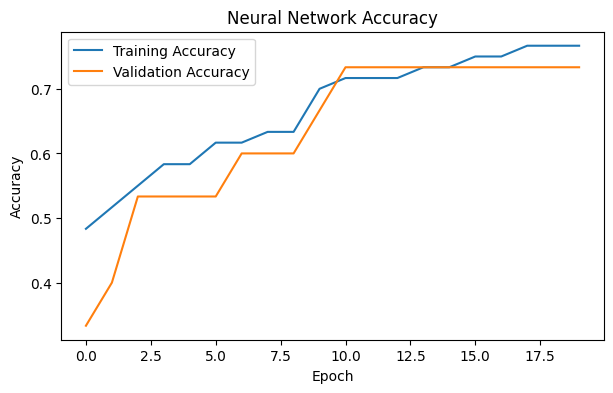

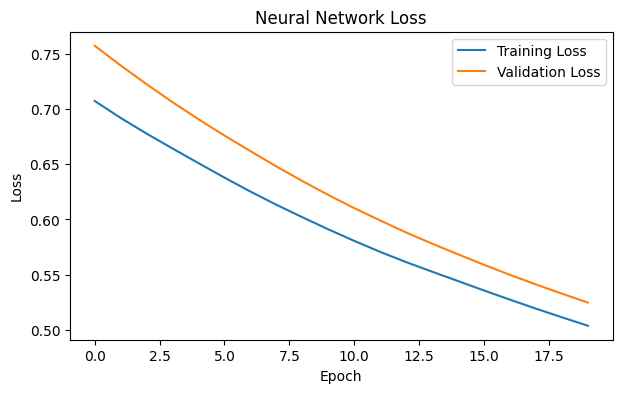

Test Accuracy: 88.00%
Test Loss: 0.4685


In [4]:

# Plot accuracy
plt.figure(figsize=(7, 4))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Neural Network Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot loss
plt.figure(figsize=(7, 4))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Neural Network Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Evaluate model
test_loss, test_accuracy = model.evaluate(
    X_test_scaled, y_test, verbose=0
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


### Q4. Interpretation

Accuracy measures how many predictions are correct, while loss measures prediction error.

If training accuracy increases and loss decreases, the model is learning. If training performance is much better than validation performance, it may indicate overfitting. If both performances are poor, it may indicate underfitting.

In [5]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Create three new records
new_records = pd.DataFrame([
    {'failed_logins': 0, 'login_hour': 11, 'new_device': 0, 'data_transfer_mb': 35},
    {'failed_logins': 7, 'login_hour': 1, 'new_device': 1, 'data_transfer_mb': 250},
    {'failed_logins': 2, 'login_hour': 23, 'new_device': 1, 'data_transfer_mb': 850}
])

# Neural Network predictions
new_scaled = scaler.transform(new_records)
probabilities = model.predict(new_scaled, verbose=0).flatten()

new_records['NN Probability'] = probabilities.round(3)
new_records['NN Prediction'] = np.where(
    probabilities >= 0.50, 'Attack', 'Normal'
)

# Train Decision Tree
tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train, y_train)

# Decision Tree accuracy
tree_pred = tree.predict(X_test)
tree_accuracy = accuracy_score(y_test, tree_pred)

# Decision Tree predictions
new_records['Tree Prediction'] = np.where(
    tree.predict(new_records[features]) == 1,
    'Attack', 'Normal'
)

# Display comparison
print(f"Neural Network Accuracy: {test_accuracy * 100:.2f}%")
print(f"Decision Tree Accuracy: {tree_accuracy * 100:.2f}%")

display(new_records)


Neural Network Accuracy: 88.00%
Decision Tree Accuracy: 88.00%


,failed_logins,login_hour,new_device,data_transfer_mb,NN Probability,NN Prediction,Tree Prediction
0,0,11,0,35,0.238,Normal,Normal
1,7,1,1,250,0.885,Attack,Attack
2,2,23,1,850,0.638,Attack,Attack


### Q5. Conclusion

The Neural Network predicts cyber activities using probabilities, while the Decision Tree uses decision rules. Both models are compared using test accuracy and predictions on three new records.

If both models agree, confidence in the prediction increases. A simpler Decision Tree may be preferred when its performance is similar because it is easier to understand and explain.